In [42]:
import pandas as pd
import numpy as np
import spacy
from spacy import displacy
import networkx as nx

import matplotlib.pyplot as plt

In [43]:
!python3 -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.6 MB/s  0:00:00 eta 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [44]:
# Load spacy English language model
NER = spacy.load('en_core_web_sm')

## Load seasons

In [45]:
import os

# Get all episode files in the data directory
all_eps = [b for b in os.scandir('data') if '.txt' in b.name]
all_eps.sort(key=lambda x: x.name)


In [46]:
all_eps

[<DirEntry '1x01 - The Pilot.txt'>,
 <DirEntry "1x02 - Cat's in the Bag.txt">,
 <DirEntry "1x03 - and the Bag's in the River.txt">,
 <DirEntry '1x04 - Cancer Man.txt'>,
 <DirEntry '1x05 - Grey Matter.txt'>,
 <DirEntry "1x06 - Crazy Handful of Nothin'.txt">,
 <DirEntry '1x07 - A-No-Rough-Stuff-Type-Deal.txt'>,
 <DirEntry '2x01 - Seven Thirty-Seven.txt'>,
 <DirEntry '2x02 - Grilled.txt'>,
 <DirEntry '2x03 - Bit by a Dead Bee.txt'>,
 <DirEntry '2x04 - Down.txt'>,
 <DirEntry '2x05 - Breakage.txt'>,
 <DirEntry '2x06 - Peekaboo.txt'>,
 <DirEntry '2x07 - n-gro Y Azul.txt'>,
 <DirEntry '2x08 - Better Call Saul.txt'>,
 <DirEntry '2x09 - 4 Days Out.txt'>,
 <DirEntry '2x10 - Over.txt'>,
 <DirEntry '2x11 - Mandala.txt'>,
 <DirEntry '2x12 - Phoenix.txt'>,
 <DirEntry '2x13 - ABQ.txt'>,
 <DirEntry '3x01 - No Mas.txt'>,
 <DirEntry '3x02 - Caballo Sin Nombre.txt'>,
 <DirEntry '3x03 - I.F.T..txt'>,
 <DirEntry '3x04 - Green Light.txt'>,
 <DirEntry '3x05 - Mas.txt'>,
 <DirEntry '3x06 - Sunset.txt'>,
 <Dir

In [47]:
# Build the main corpus from all transcript files (not just one episode)
all_text = []
for ep in all_eps:
    with open(ep.path, encoding='utf-8', errors='ignore') as f:
        all_text.append(f.read())

ep_text = '\n\n'.join(all_text)
ep_doc = NER(ep_text)
print(f'Loaded {len(all_eps)} files for the main graph.')


Loaded 62 files for the main graph.


In [48]:
# Visualize identified entities
displacy.render(ep_doc[0:2000], style="ent", jupyter=True)

## Load character names

In [49]:
# Read Characters
character_df = pd.read_csv("characters_bd.csv")

In [50]:
# Remove brackets and text within brackets
import re
character_df['character'] = character_df['character'].apply(lambda x: re.sub("[\(].*?[\)]", "", x))
character_df['character_firstname'] = character_df['character'].apply(lambda x: x.split(' ', 1)[0])

<>:3: SyntaxWarning: invalid escape sequence '\('
<>:3: SyntaxWarning: invalid escape sequence '\('
/var/folders/z9/7xzcq609769g2r_yc5fgj9640000gn/T/ipykernel_17427/493100674.py:3: SyntaxWarning: invalid escape sequence '\('
  character_df['character'] = character_df['character'].apply(lambda x: re.sub("[\(].*?[\)]", "", x))


In [51]:
pd.set_option('display.max_rows', None)
character_df

,season,character,character_firstname
0,Season 1,List of bit parts in Breaking Bad/Season 1,List
1,Season 1,Hugo Archilleya,Hugo
2,Season 1,Badger,Badger
3,Season 1,Dr. Belknap,Dr.
4,Season 1,Ben,Ben
5,Season 1,Billy,Billy
6,Season 1,Cantina Guards,Cantina
7,Season 1,Chad,Chad
8,Season 1,Chad's Girlfriend,Chad's
9,Season 1,Combo,Combo


## Get named entity list per sentence

In [52]:
sent_entity_df = []

# Loop through sentences, store named entity list for each sentence
for sent in ep_doc.sents:
     entity_list = [ent.text for ent in sent.ents]
     sent_entity_df.append({"sentence": sent, "entities": entity_list})

sent_entity_df = pd.DataFrame(sent_entity_df)

In [ ]:
sent_entity_df

In [54]:
# Function to filter out non-character entities
def filter_entity(ent_list, character_df):
    return [ent for ent in ent_list
            if ent in list (character_df.character)
            or ent in list (character_df.character_firstname)]

In [55]:
filter_entity(["Walter", "Thu", "2"], character_df)

['Walter']

In [ ]:
sent_entity_df['character_entities'] = sent_entity_df['entities'].apply(lambda x: filter_entity(x, character_df))

# Filter out sentences tha don't have any character entities
sent_entity_df_filtered = sent_entity_df[sent_entity_df['character_entities'].map(len) > 0]
sent_entity_df_filtered.head(10)

In [57]:
# Take only first name of characters
sent_entity_df_filtered['character_entities'] = sent_entity_df_filtered['character_entities'].apply(lambda x: [item.split()[0] for item in x])

In [58]:
pd.reset_option('^display.')
sent_entity_df_filtered

,sentence,entities,character_entities
12,"(Skyler, :, Happy, Birthday, ., \n\n)",[Skyler],[Skyler]
14,"(Skyler, :, That, is, veggie, bacon, .)",[Skyler],[Skyler]
20,"(Skyler, :, I, do, n't, want, him, dicking, yo...","[Skyler, tonight]",[Skyler]
23,"(Walter, :, Well, ,, thank, you, ., \n\n)",[Walter],[Walter]
24,"(Skyler, :, You, 're, late, again, ., \n\n)",[Skyler],[Skyler]
...,...,...,...
28434,"(Gretchen, ,, would, you, mind, ?)",[Gretchen],[Gretchen]
28482,"([, Gretchen, sobs, ])",[Gretchen],[Gretchen]
28503,"(Jesse, ., \n\n)",[Jesse],[Jesse]
28507,"(Right, on, ,, Jesse, ., \n\n)",[Jesse],[Jesse]


## Create relationships

In [59]:
window_size = 5
relationships = []

for i in range(sent_entity_df_filtered.index[-1] + 1):
    end_i = min(i+5, sent_entity_df_filtered.index[-1])
    char_list = sum((sent_entity_df_filtered.loc[i: end_i].character_entities), [])

    # Remove duplicated characters that are next to each other
    char_unique = [char_list[i] for i in range(len(char_list))
                    if (i==0) or char_list[i] != char_list[i-1]]

    if len(char_unique) > 1:
        for idx, a in enumerate(char_unique[:-1]):
            b = char_unique[idx + 1]
            relationships.append({"source": a, "target": b})


In [60]:
relationship_df = pd.DataFrame(relationships)

In [ ]:
pd.set_option('display.max_rows', None)
relationship_df

In [ ]:
# Sort the cases with a->b and b->a
relationship_df = pd.DataFrame(np.sort(relationship_df.values, axis = 1), columns = relationship_df.columns)
relationship_df

In [63]:
relationship_df["value"] = 1
relationship_df = relationship_df.groupby(["source", "target"], sort=False, as_index=False).sum()

In [64]:
relationship_df.head(10)

,source,target,value
0,Skyler,Walter,838
1,Ben,Walter,16
2,Bogdan,Walter,24
3,Chad,Walter,1
4,Chad,Skyler,2
5,Marie,Skyler,1004
6,Marie,Steve,59
7,Bogdan,Skyler,15
8,Steve,Walter,1
9,Emilio,Steve,7


## Graph analysis and visualization

In [65]:
# Create a graph from a pandas dataframe
G = nx.from_pandas_edgelist(relationship_df,
                            source = "source",
                            target = "target",
                            edge_attr = "value",
                            create_using = nx.Graph())

### Graph visualization - Networkx

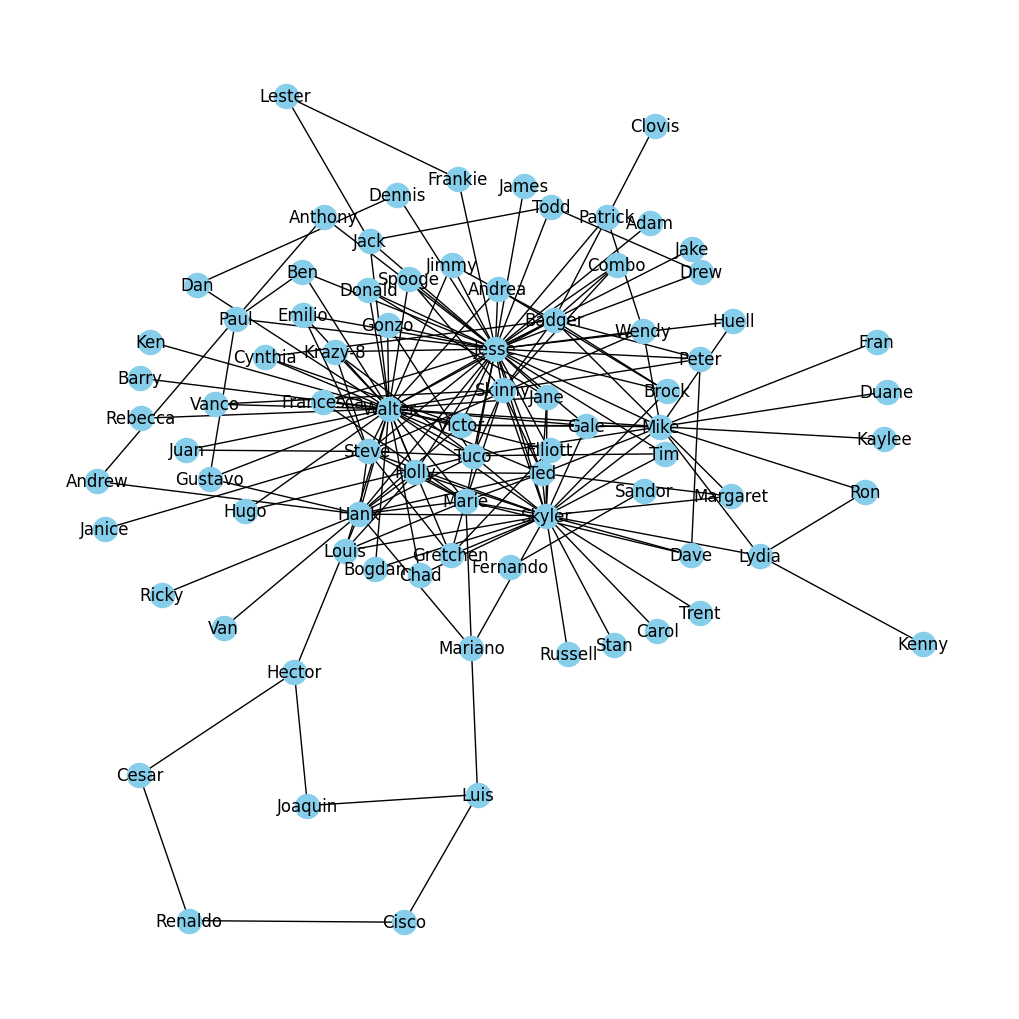

In [66]:
plt.figure(figsize=(10,10))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, with_labels=True, node_color='skyblue', edge_cmap=plt.cm.Blues, pos = pos)
plt.show()

#### Graph visualization - Pyvis

In [67]:
from pyvis.network import Network
net = Network(notebook = True, width = "1000px", height = "700px", bgcolor = '#222222', font_color = 'white')

node_degree = dict(G.degree)

# Setting up node size attribute
nx.set_node_attributes(G, node_degree, 'size')
net.from_nx(G)
net.show("breaking.html")

breaking.html


### The most important characters in Breaking Bad

In [68]:
# Degree centrality
degree_dict = nx.degree_centrality(G)
degree_dict

{'Skyler': 0.3333333333333333,
 'Walter': 0.4691358024691358,
 'Ben': 0.037037037037037035,
 'Bogdan': 0.024691358024691357,
 'Chad': 0.024691358024691357,
 'Marie': 0.16049382716049382,
 'Steve': 0.14814814814814814,
 'Emilio': 0.037037037037037035,
 'Jesse': 0.5061728395061729,
 'Krazy-8': 0.04938271604938271,
 'Gretchen': 0.06172839506172839,
 'Louis': 0.04938271604938271,
 'Wendy': 0.04938271604938271,
 'Hank': 0.18518518518518517,
 'Skinny': 0.13580246913580246,
 'Ken': 0.012345679012345678,
 'Jake': 0.012345679012345678,
 'Adam': 0.012345679012345678,
 'Badger': 0.12345679012345678,
 'Elliott': 0.04938271604938271,
 'Hugo': 0.024691358024691357,
 'Tuco': 0.13580246913580246,
 'Gonzo': 0.037037037037037035,
 'Holly': 0.08641975308641975,
 'Dave': 0.037037037037037035,
 'Tim': 0.037037037037037035,
 'Dan': 0.024691358024691357,
 'Paul': 0.06172839506172839,
 'Anthony': 0.024691358024691357,
 'Ricky': 0.012345679012345678,
 'Jane': 0.06172839506172839,
 'Spooge': 0.03703703703703703

<Axes: >

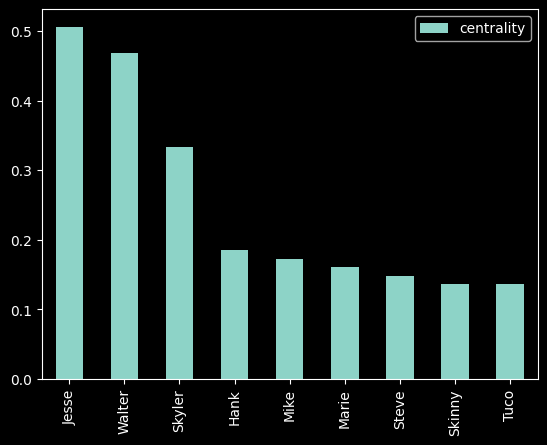

In [69]:
degree_df = pd.DataFrame.from_dict(degree_dict, orient='index', columns = ['centrality'])
# Plot top 10 nodes
degree_df.sort_values('centrality', ascending = False) [0:9].plot(kind="bar")

<Axes: >

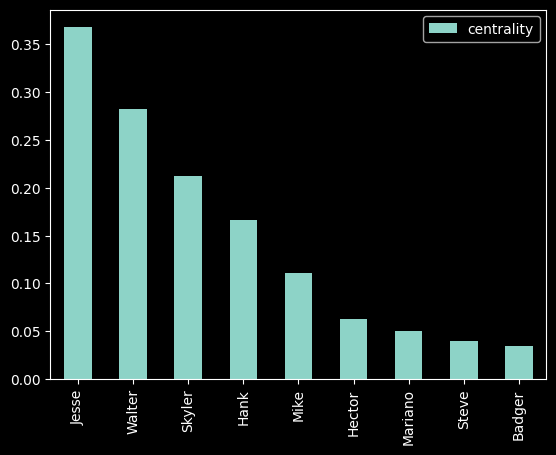

In [70]:
# Betweenness centrality
betweenness_dict = nx.betweenness_centrality(G)
betweenness_df = pd.DataFrame.from_dict(betweenness_dict, orient='index', columns = ['centrality'])
# Plot top 10 nodes
betweenness_df.sort_values('centrality', ascending = False) [0:9].plot(kind="bar")

<Axes: >

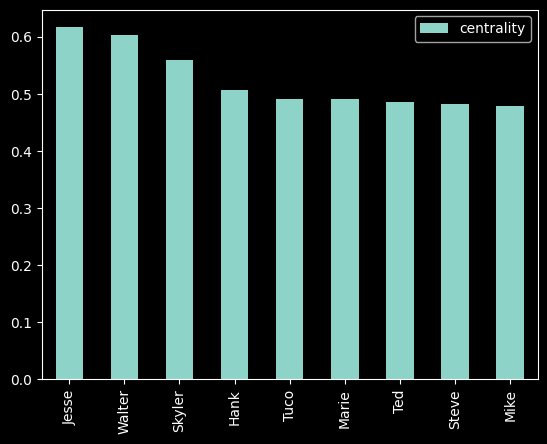

In [71]:
# Closeness centrality
closeness_dict = nx.closeness_centrality(G)
closeness_df = pd.DataFrame.from_dict(closeness_dict, orient='index', columns = ['centrality'])
# Plot top 10 nodes
closeness_df.sort_values('centrality', ascending = False) [0:9].plot(kind="bar")

In [72]:
# Save centrality measures
nx.set_node_attributes(G, degree_dict, 'degree_centrality')
nx.set_node_attributes(G, betweenness_dict, 'betweenness_centrality')
nx.set_node_attributes(G, closeness_dict, 'closeness_centrality')

### Community Detection

In [73]:
import community as community_louvain

In [74]:
communities = community_louvain.best_partition(G)

In [75]:
communities

{'Skyler': 0,
 'Walter': 1,
 'Ben': 4,
 'Bogdan': 0,
 'Chad': 1,
 'Marie': 0,
 'Steve': 1,
 'Emilio': 1,
 'Jesse': 6,
 'Krazy-8': 1,
 'Gretchen': 0,
 'Louis': 0,
 'Wendy': 6,
 'Hank': 4,
 'Skinny': 2,
 'Ken': 1,
 'Jake': 6,
 'Adam': 6,
 'Badger': 2,
 'Elliott': 0,
 'Hugo': 1,
 'Tuco': 1,
 'Gonzo': 1,
 'Holly': 0,
 'Dave': 2,
 'Tim': 1,
 'Dan': 6,
 'Paul': 4,
 'Anthony': 4,
 'Ricky': 4,
 'Jane': 6,
 'Spooge': 2,
 'Barry': 1,
 'Vanco': 2,
 'Margaret': 2,
 'Ted': 0,
 'Jack': 6,
 'Francesca': 0,
 'Jimmy': 2,
 'James': 6,
 'Donald': 6,
 'Combo': 2,
 'Gustavo': 4,
 'Cynthia': 3,
 'Victor': 3,
 'Mike': 3,
 'Andrew': 4,
 'Kaylee': 3,
 'Russell': 0,
 'Janice': 1,
 'Clovis': 2,
 'Gale': 3,
 'Juan': 1,
 'Peter': 2,
 'Andrea': 6,
 'Brock': 6,
 'Patrick': 6,
 'Stan': 0,
 'Cesar': 4,
 'Hector': 4,
 'Renaldo': 4,
 'Cisco': 4,
 'Luis': 4,
 'Joaquin': 4,
 'Rebecca': 1,
 'Duane': 3,
 'Fran': 3,
 'Lydia': 3,
 'Dennis': 6,
 'Huell': 3,
 'Fernando': 5,
 'Sandor': 5,
 'Ron': 3,
 'Mariano': 4,
 'Drew': 6,
 '

In [76]:
nx.set_node_attributes(G,communities, 'group')

In [78]:
com_net = Network(notebook = True, width = "1000px", height = "700px", bgcolor = '#222222', font_color = 'white')
com_net.from_nx(G)
com_net.show("breaking.html")

breaking.html


### Evolution of characters' importance

In [79]:
from lib.utils.functions import *

In [80]:
# Initialize empty list for graphs from episodes
eps_graph = []
all_eps = [b for b in os.scandir('data') if '.txt' in b.name]
# Load spacy English language model
nlp = spacy.load('en_core_web_sm')

# Sort dir entries by name
all_eps.sort(key=lambda x: x.name)

In [81]:
# Loop through book list and create graphs
for ep in all_eps:
    ep_test = ner(ep)

    # Get list of entities per sentences
    sent_entity_df = get_ne_list_per_sentence(ep_test)

    # Select only character entities
    sent_entity_df['character_entities'] = sent_entity_df['entities'].apply(lambda x: filter_entity(x, character_df))

    # Filter out sentences that don't have any character entities
    sent_entity_df_filtered = sent_entity_df[sent_entity_df['character_entities'].map(len) > 0]

    # Take only first name of characters
    sent_entity_df_filtered['character_entities'] = sent_entity_df_filtered['character_entities'].apply(lambda x: [item.split()[0] for item in x])

    # Create relationship df
    relationship_df = create_relationships(df = sent_entity_df_filtered, window_size = 5)

    # Create a graph from a pandas dataframe
    G = nx.from_pandas_edgelist(relationship_df,
                                source = "source",
                                target = "target",
                                edge_attr = "value",
                                create_using= nx.Graph())
    eps_graph.append(G)

<Axes: >

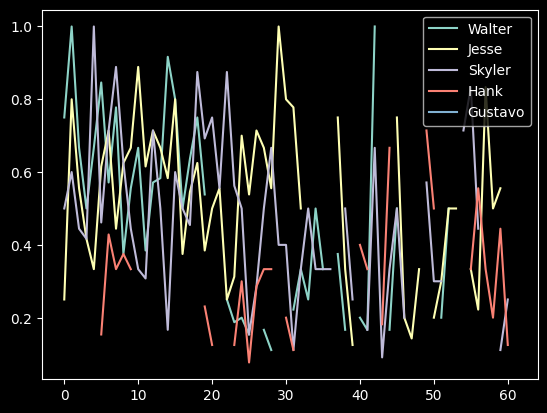

In [83]:
# Creating a list of degree centrality of all the books
evol = [nx.degree_centrality(ep) for ep in eps_graph]

# Creating a DataFrame from the list of degree centralities in all the books
degree_evol_df = pd.DataFrame.from_records(evol)

# Plotting the degree centrality evolution of 5 main characters
degree_evol_df[["Walter", "Jesse", "Skyler", "Hank", "Gustavo"]].plot()